# TCN para formación de colas (CAETEC)

Entrena y evalúa `TCNModel` con `TimeSeriesSplit` de 5 folds, muestra métricas por fold y las compara contra líneas base.

## 1. Configuración

In [1]:
# ====== RUTAS (ajusta a tu Drive) ======
DATA_PATH = "/content/drive/MyDrive/Datos/Procesado/dataset_final_serie_tiempo.parquet"
MODELING_PARENT = "/content/modeling"

# ====== EXPERIMENTO-00 ======
TASK = "classification" # "classification" (hay_cola) | "regression" (pct_posible_cola)
WINDOW = 48 # 12 (6 h) | 48 (24 h)
VERSION = "base" # "base" | "dense" | "norm"
LEVELS = None # Automático según la ventana
EPOCHS = 50
BATCH = 64
N_SPLITS = 5
QUICK = False # False = Entrenamiento completo | True = prueba rápida (1 fold, 3 épocas)
SEED = 42 # The magic number :)
TARGET = "pct_posible_cola"

## 2. Imports y datos

In [2]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
if MODELING_PARENT not in sys.path:
    sys.path.insert(0, MODELING_PARENT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)
from tensorflow.keras.callbacks import EarlyStopping

from modeling.tcn_model import TCNModel

np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
df = pd.read_parquet(DATA_PATH)
print(df.shape)
print(df.dtypes.to_string())
df.head()

(179850, 24)
ms                                    object
bloque_tiempo                 datetime64[ns]
total_ordenios                         int64
produccion_promedio                  float64
duracion_total_min                   float64
patadas_totales                        int64
desviaciones_leche_totales           float64
ordenios_con_lavado                    int64
pct_primer_parto                     float64
pct_fresca                           float64
pct_alta                             float64
pct_baja                             float64
pct_extendida                        float64
hubo_ordenios                          int64
pct_ocupacion_robot                  float64
hubo_lavado                            int64
ordenios_otros_robots                  int64
hora                                   int32
dia_semana                             int32
temporada                             object
min_desde_alimento                   float64
vacas_activas_dia                      int

,ms,bloque_tiempo,total_ordenios,produccion_promedio,duracion_total_min,patadas_totales,desviaciones_leche_totales,ordenios_con_lavado,pct_primer_parto,pct_fresca,...,pct_ocupacion_robot,hubo_lavado,ordenios_otros_robots,hora,dia_semana,temporada,min_desde_alimento,vacas_activas_dia,sin_etapa,pct_posible_cola
0,VMS 3,2022-08-01 00:00:00,2,13.375,19.066667,0,0.0,0,0.0,0.0,...,0.635556,0,0,0,0,verano,570.0,31,1,1.000000
1,VMS 3,2022-08-01 00:30:00,1,21.470,6.366667,0,0.0,0,0.0,0.0,...,0.212222,0,0,0,0,verano,600.0,31,1,0.000000
2,VMS 1,2022-08-01 01:00:00,3,11.030,16.783333,0,0.0,0,0.0,0.0,...,0.559444,0,1,1,0,verano,630.0,31,1,0.666667
3,VMS 3,2022-08-01 01:00:00,1,16.690,6.650000,0,0.0,0,0.0,0.0,...,0.221667,0,3,1,0,verano,630.0,31,1,0.000000
4,VMS 1,2022-08-01 01:30:00,0,NaN,0.000000,0,0.0,0,0.0,0.0,...,0.000000,0,0,1,0,verano,660.0,31,1,0.000000


## 3. Ventanas 3D por robot

La ventana termina en el bloque *t−1* y la etiqueta es la del bloque *t*, así no se usan las variables mecánicas del bloque que se quiere predecir.

In [4]:
tcn = TCNModel(task=TASK, window=WINDOW)
X_seq, y_seq, meta = tcn.prepare(df, df[TARGET])
print("X_seq:", X_seq.shape, "(N, ventana, features)")
print("y_seq:", y_seq.shape)
print("Features:", tcn.feature_names_)
print("Periodo objetivo:", meta["bloque_tiempo"].min(), "->", meta["bloque_tiempo"].max())
print("Ventanas por robot:\n", meta["ms"].value_counts().to_string())
if TASK == "classification":
    print(f"Proporción hay_cola=1: {y_seq.mean():.3f}")
else:
    print(f"pct_posible_cola promedio: {y_seq.mean():.3f}")

X_seq: (179706, 48, 27) (N, ventana, features)
y_seq: (179706,)
Features: ['total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola', 'temp_invierno', 'temp_primavera', 'temp_verano', 'temp_otoño', 'hora_sin', 'hora_cos']
Periodo objetivo: 2022-08-02 00:00:00 -> 2025-12-31 23:30:00
Ventanas por robot:
 ms
VMS 3    59904
VMS 1    59902
VMS 2    59900
Proporción hay_cola=1: 0.253


## 4. Líneas base

- **Mayoritaria / media**: predice siempre lo más frecuente del train.
- **Persistencia**: repite el valor del bloque anterior del mismo robot (dato disponible al predecir).

In [5]:
# Valor del bloque anterior (t-1) del mismo robot, alineado con cada ventana
lookup = df[["ms", "bloque_tiempo", TARGET]].copy()
lookup["bloque_tiempo"] = pd.to_datetime(lookup["bloque_tiempo"]) + pd.Timedelta(minutes=30)
lookup = lookup.rename(columns={TARGET: "prev"})
prev = meta[["ms", "bloque_tiempo"]].merge(lookup, on=["ms", "bloque_tiempo"], how="left")["prev"].to_numpy()
persist = np.nan_to_num(prev, nan=np.nanmean(prev))
persist_bin = (persist > tcn.threshold).astype(float)
print("Persistencia disponible en", (~np.isnan(prev)).mean().round(3), "de las ventanas")

Persistencia disponible en 1.0 de las ventanas


## 5. Funciones de métricas

In [6]:
def cls_metrics(y_true, y_prob, thr=0.5):
    y_true = np.asarray(y_true).astype(int); y_pred = (np.asarray(y_prob) >= thr).astype(int)
    try: auc = roc_auc_score(y_true, y_prob)
    except ValueError: auc = np.nan
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "AUC": auc}

def reg_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

def metrics(y_true, y_hat):
    return cls_metrics(y_true, y_hat) if TASK == "classification" else reg_metrics(y_true, y_hat)

## 6. Entrenamiento con TimeSeriesSplit

In [7]:
epochs = 3 if QUICK else EPOCHS
tscv = TimeSeriesSplit(n_splits=N_SPLITS)
folds = list(tscv.split(X_seq))
if QUICK:
    folds = folds[:1]
    print("MODO RÁPIDO: 1 fold, 3 épocas")

rows_model, rows_active, rows_base, rows_persist = [], [], [], []
histories, last = [], {}

for k, (tr, te) in enumerate(folds, start=1):
    print(f"\n===== Fold {k}/{len(folds)} | train={len(tr):,} test={len(te):,} =====")
    print("Test:", meta["bloque_tiempo"].iloc[te].min(), "->", meta["bloque_tiempo"].iloc[te].max())
    tf.keras.backend.clear_session()

    X_tr, X_te = tcn.scale(X_seq[tr], X_seq[te])      # scaler ajustado solo con train
    y_tr, y_te = y_seq[tr], y_seq[te]

    model = tcn.compile(input_shape=X_tr.shape[1:], v=VERSION, levels=LEVELS)
    if k == 1:
        model.summary()

    hist = model.fit(X_tr, y_tr, epochs=epochs, batch_size=BATCH, validation_split=0.1,
                     callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
                     verbose=2)
    histories.append(hist.history)

    y_hat = model.predict(X_te, batch_size=512, verbose=0).ravel()
    rows_model.append({"fold": k, **metrics(y_te, y_hat)})

    # Solo bloques con ordeños (análisis retrospectivo)
    if "hubo_ordenios" in meta.columns:
        act = meta["hubo_ordenios"].to_numpy()[te] == 1
        rows_active.append({"fold": k, **metrics(y_te[act], y_hat[act])})

    # Líneas base
    if TASK == "classification":
        majority = float(y_tr.mean() > 0.5)
        rows_base.append({"fold": k, **cls_metrics(y_te, np.full(len(y_te), majority))})
        rows_persist.append({"fold": k, **cls_metrics(y_te, persist_bin[te])})
    else:
        rows_base.append({"fold": k, **reg_metrics(y_te, np.full(len(y_te), y_tr.mean()))})
        rows_persist.append({"fold": k, **reg_metrics(y_te, persist[te])})

    last = dict(model=model, history=hist, X_te=X_te, y_te=y_te, y_hat=y_hat, te=te)


===== Fold 1/5 | train=29,951 test=29,951 =====
Test: 2023-02-26 00:30:00 -> 2023-09-22 00:30:00


Model: "tcn_k3_n4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 27)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 48, 64)    │      5,248 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 48, 64)    │          0 │ conv1d[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 48, 64)    │          0 │ activation[0][0]  │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 48, 64)    │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 48, 64)    │          0 │ conv1d_1[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_1 │ (None, 48, 64)    │          0 │ activation_1[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 48, 64)    │      1,792 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 64)    │          0 │ spatial_dropout1… │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 48, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 48, 64)    │     12,352 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 48, 64)    │          0 │ conv1d_3[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_2 │ (None, 48, 64)    │          0 │ activation_3[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 48, 64)    │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 48, 64)    │          0 │ conv1d_4[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_3 │ (None, 48, 64)    │          0 │ activation_4[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 48, 64)    │          0 │ spatial_dropout1… │
│                     │                   │            │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 48, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 95,617 (373.50 KB)

 Trainable params: 95,617 (373.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
422/422 - 48s - 114ms/step - accuracy: 0.9569 - auc: 0.5303 - loss: 0.1901 - precision: 0.0755 - recall: 0.0036 - val_accuracy: 0.9513 - val_auc: 0.5982 - val_loss: 0.1997 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
422/422 - 3s - 6ms/step - accuracy: 0.9586 - auc: 0.5991 - loss: 0.1753 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9513 - val_auc: 0.6111 - val_loss: 0.1979 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/50
422/422 - 2s - 5ms/step - accuracy: 0.9586 - auc: 0.6515 - loss: 0.1690 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9513 - val_auc: 0.6285 - val_loss: 0.1983 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/50
422/422 - 3s - 6ms/step - accuracy: 0.9586 - auc: 0.6778 - loss: 0.1655 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9513 - val_auc: 0.6086 - val_loss: 0.1990 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/50
422/422 - 2s - 5ms/step - accu

## 7. Resultados por fold

In [8]:
def summarize(rows, name):
    d = pd.DataFrame(rows).set_index("fold")
    d.loc["media"] = d.mean(); d.loc["std"] = d.iloc[:-1].std()
    print(f"\n--- {name} ---"); display(d.round(4)); return d

res_model   = summarize(rows_model,   f"TCN ({VERSION}, ventana={WINDOW}) - todos los bloques")
if rows_active:
    res_active = summarize(rows_active, "TCN - solo bloques con ordeños")
res_base    = summarize(rows_base,    "Base: " + ("clase mayoritaria" if TASK == "classification" else "media del train"))
res_persist = summarize(rows_persist, "Base: persistencia (bloque anterior)")


--- TCN (base, ventana=48) - todos los bloques ---


,Accuracy,Precision,Recall,F1,AUC
fold,,,,,
1,0.9164,0.0000,0.0000,0.0000,0.5841
2,0.8332,0.0000,0.0000,0.0000,0.6029
3,0.7441,1.0000,0.0001,0.0003,0.5900
4,0.6045,0.6223,0.0408,0.0766,0.6504
5,0.6335,0.6959,0.6278,0.6601,0.6984
media,0.7463,0.4636,0.1337,0.1474,0.6251
std,0.1316,0.4463,0.2767,0.2885,0.0485



--- TCN - solo bloques con ordeños ---


,Accuracy,Precision,Recall,F1,AUC
fold,,,,,
1,0.8670,0.0000,0.0000,0.0000,0.5477
2,0.7748,0.0000,0.0000,0.0000,0.5833
3,0.6874,1.0000,0.0001,0.0003,0.5719
4,0.5399,0.6360,0.0408,0.0767,0.5931
5,0.6016,0.7154,0.6278,0.6687,0.6338
media,0.6941,0.4703,0.1337,0.1491,0.5859
std,0.1312,0.4501,0.2767,0.2924,0.0316



--- Base: clase mayoritaria ---


,Accuracy,Precision,Recall,F1,AUC
fold,,,,,
1,0.9164,0.0,0.0,0.0,0.5
2,0.8332,0.0,0.0,0.0,0.5
3,0.7441,0.0,0.0,0.0,0.5
4,0.5980,0.0,0.0,0.0,0.5
5,0.4332,0.0,0.0,0.0,0.5
media,0.7050,0.0,0.0,0.0,0.5
std,0.1923,0.0,0.0,0.0,0.0



--- Base: persistencia (bloque anterior) ---


,Accuracy,Precision,Recall,F1,AUC
fold,,,,,
1,0.8510,0.1090,0.1090,0.1090,0.5139
2,0.7469,0.2415,0.2415,0.2415,0.5448
3,0.6475,0.3113,0.3113,0.3113,0.5372
4,0.5734,0.4693,0.4693,0.4693,0.5563
5,0.6134,0.6590,0.6590,0.6590,0.6064
media,0.6864,0.3580,0.3580,0.3580,0.5517
std,0.1122,0.2126,0.2125,0.2126,0.0343


## 8. Comparación contra líneas base

Con ~54 % de posible cola, la exactitud sola engaña. Mira F1 (criterio de éxito: **F1 > 0.60**) y que el TCN supere a la persistencia.

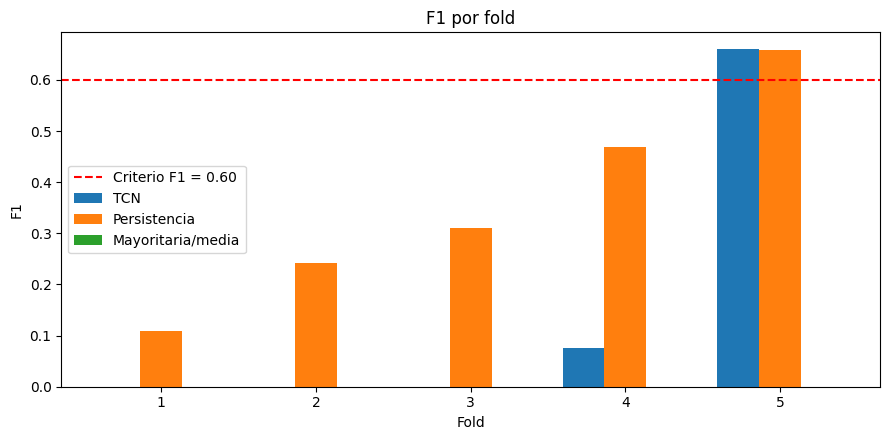

F1 medio  TCN: 0.1474 | persistencia: 0.3580 | base: 0.0000


In [9]:
key = "F1" if TASK == "classification" else "MAE"
n = len(folds); x = np.arange(1, n + 1); w = 0.27

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, res_model[key].iloc[:n],   w, label="TCN")
ax.bar(x,     res_persist[key].iloc[:n], w, label="Persistencia")
ax.bar(x + w, res_base[key].iloc[:n],    w, label="Mayoritaria/media")
if TASK == "classification":
    ax.axhline(0.60, color="red", ls="--", label="Criterio F1 = 0.60")
ax.set_xticks(x); ax.set_xlabel("Fold"); ax.set_ylabel(key)
ax.set_title(f"{key} por fold"); ax.legend(); plt.tight_layout(); plt.show()

print(f"{key} medio  TCN: {res_model.loc['media', key]:.4f} | "
      f"persistencia: {res_persist.loc['media', key]:.4f} | "
      f"base: {res_base.loc['media', key]:.4f}")

## 9. Curvas de entrenamiento (todos los folds)

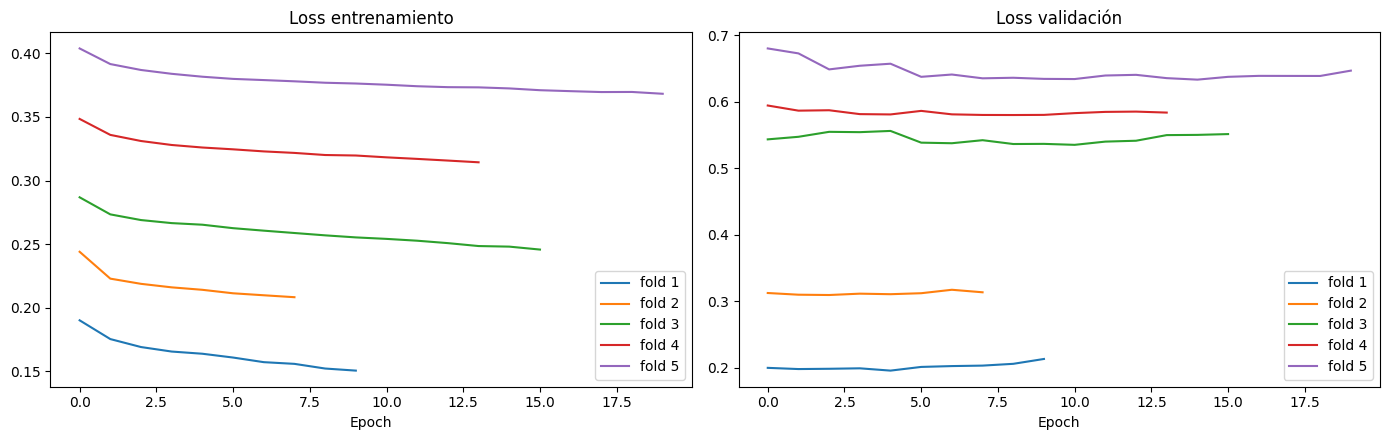

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for k, h in enumerate(histories, start=1):
    axes[0].plot(h["loss"], label=f"fold {k}")
    axes[1].plot(h["val_loss"], label=f"fold {k}")
axes[0].set_title("Loss entrenamiento"); axes[1].set_title("Loss validación")
for a in axes: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

## 10. Detalle del último fold (curvas, matriz de confusión / ROC o residuales)


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.633535
Precision 0.695919
   Recall 0.627791
 F1-Score 0.660102
  ROC-AUC 0.698372


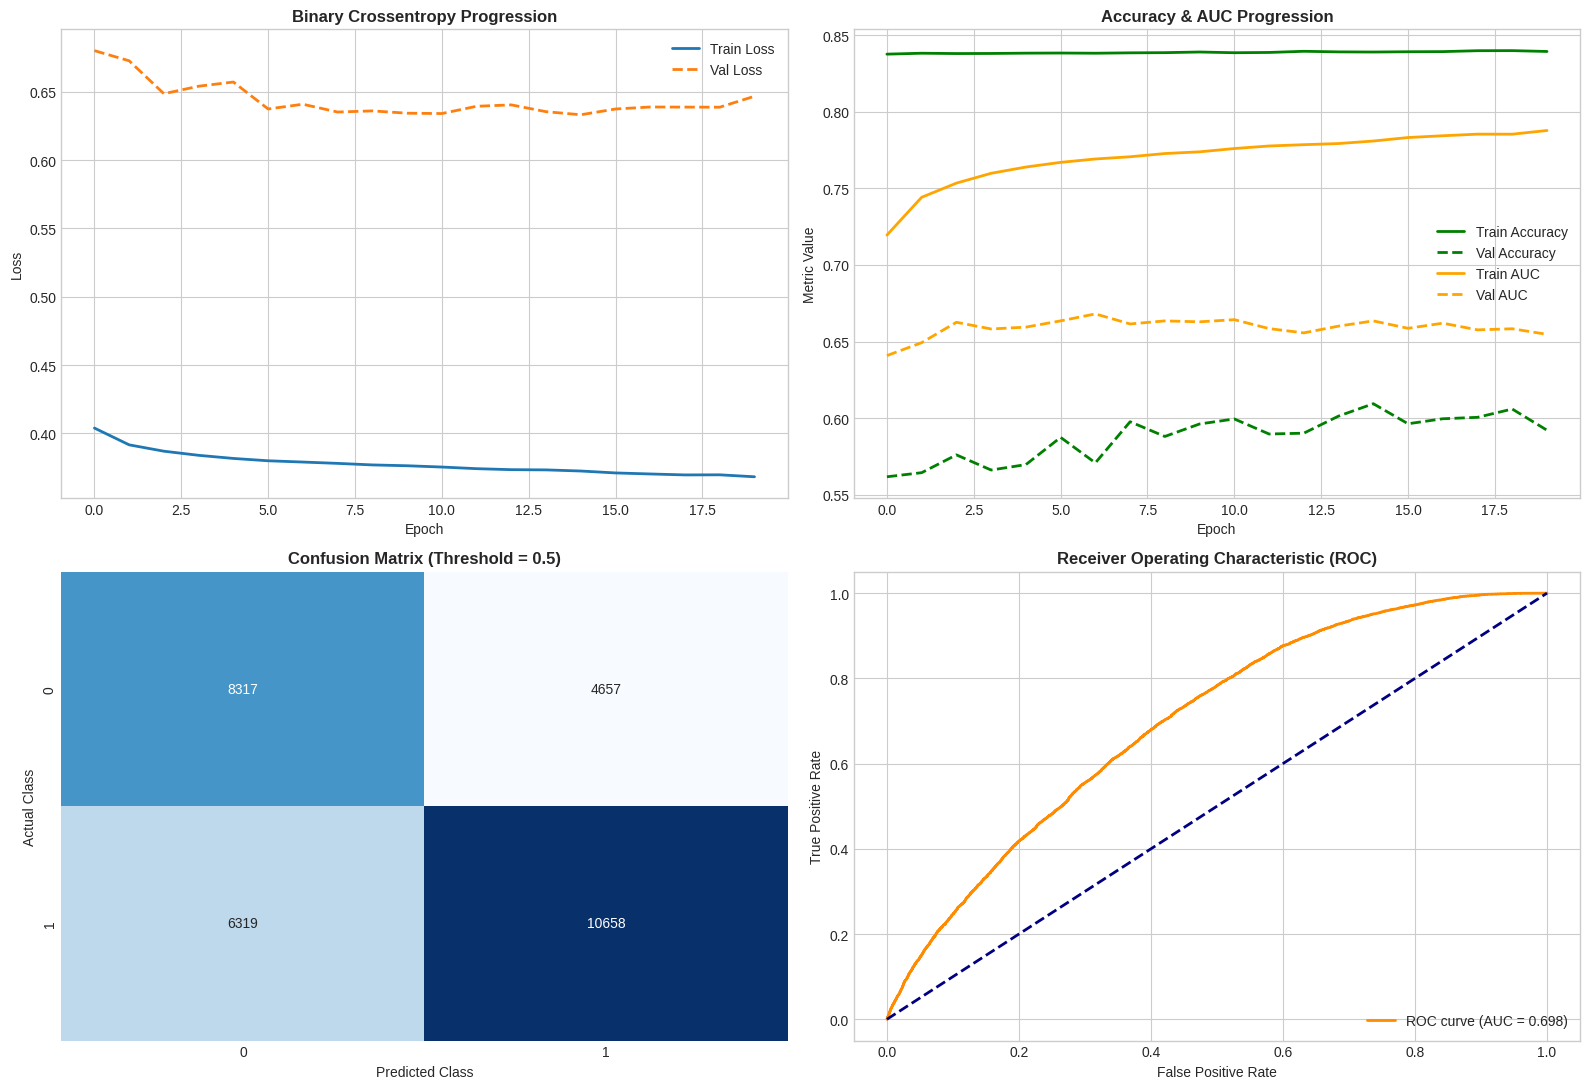

In [11]:
df_pred, df_metrics = tcn.evaluate(last["model"], last["history"], last["X_te"], last["y_te"])

## 11. Predicción vs. real en una semana (un robot)

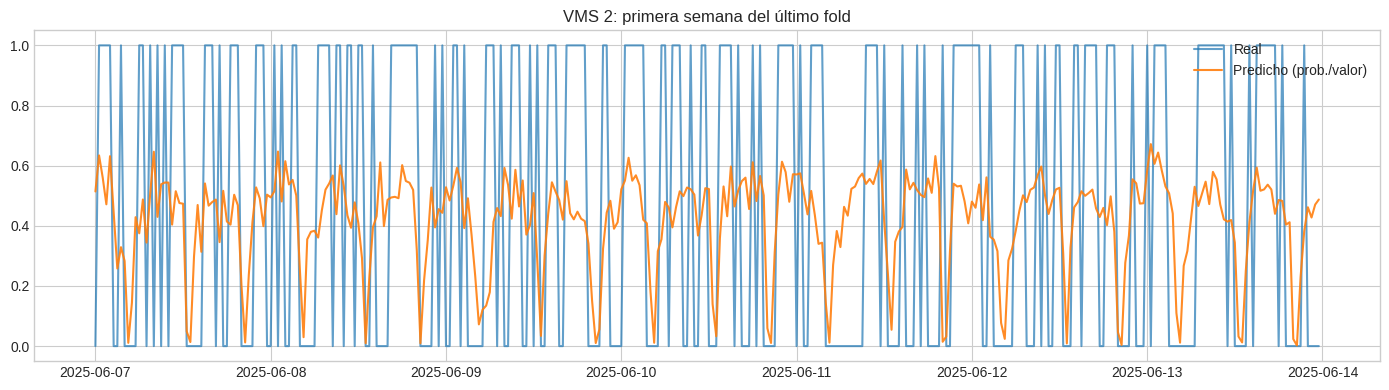

In [12]:
m = meta.iloc[last["te"]].copy()
m["real"] = last["y_te"]; m["pred"] = last["y_hat"]
robot = m["ms"].iloc[0]
s = m[m["ms"] == robot].head(336)          # 336 bloques = 7 días

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(s["bloque_tiempo"], s["real"], label="Real", alpha=0.7)
ax.plot(s["bloque_tiempo"], s["pred"], label="Predicho (prob./valor)", alpha=0.9)
ax.set_title(f"{robot}: primera semana del último fold"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Importancia de variables (por permutación, último fold)

Desordena una variable a la vez y mide cuánto empeora la métrica. Más caída = más importante. Se muestrea para que corra rápido.

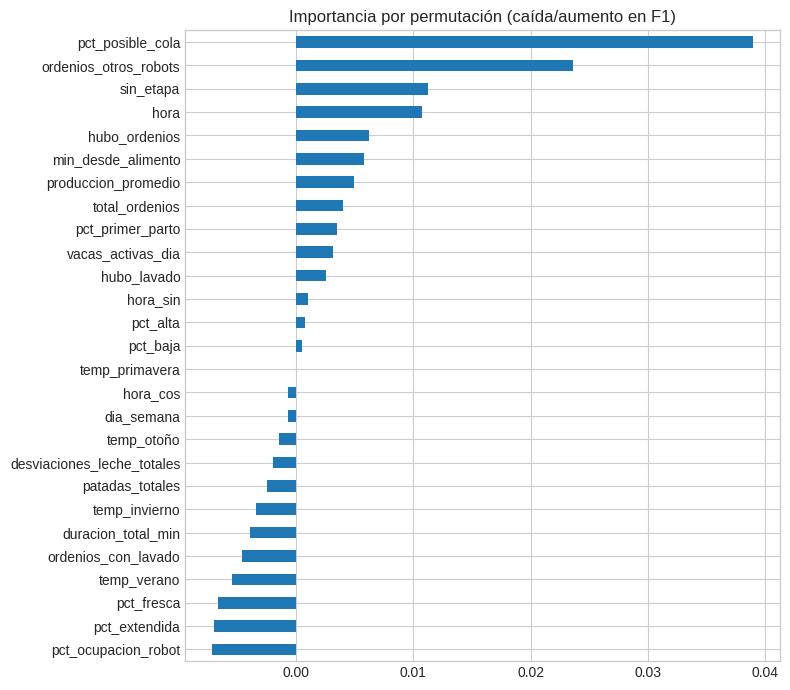

In [13]:
rng = np.random.default_rng(SEED)
Xp, yp = last["X_te"], last["y_te"]
idx = rng.choice(len(Xp), size=min(5000, len(Xp)), replace=False)
Xs, ys = Xp[idx], yp[idx]
mkey = "F1" if TASK == "classification" else "MAE"

base_val = metrics(ys, last["model"].predict(Xs, batch_size=512, verbose=0).ravel())[mkey]
imp = {}
for j, name in enumerate(tcn.feature_names_):
    Xperm = Xs.copy()
    Xperm[:, :, j] = Xperm[rng.permutation(len(Xs)), :, j]    # permuta la variable entre muestras
    v = metrics(ys, last["model"].predict(Xperm, batch_size=512, verbose=0).ravel())[mkey]
    imp[name] = (base_val - v) if TASK == "classification" else (v - base_val)

imp = pd.Series(imp).sort_values()
imp.plot.barh(figsize=(8, 7)); plt.title(f"Importancia por permutación (caída/aumento en {mkey})")
plt.tight_layout(); plt.show()

## 13. Guardar resultados

In [14]:
out = res_model.copy(); out.insert(0, "config", f"{TASK}|{VERSION}|w{WINDOW}|lv{LEVELS}")
out.to_csv(f"resultados_tcn_{TASK}_{VERSION}_w{WINDOW}.csv")
print("Guardado en el directorio actual de Colab (cópialo a Drive si lo quieres conservar).")

Guardado en el directorio actual de Colab (cópialo a Drive si lo quieres conservar).


## 14. Exportar Modelo

In [15]:
import json, joblib
from pathlib import Path

MODELS_DIR = Path(MODELING_PARENT) / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tag = f"tcn_{TASK}_{VERSION}_w{WINDOW}" + ("_quick" if QUICK else "")
model_file  = MODELS_DIR / f"{tag}.keras"
scaler_file = MODELS_DIR / f"{tag}_scaler.joblib"
config_file = MODELS_DIR / f"{tag}_config.json"

last["model"].save(model_file)
joblib.dump(tcn.scaler, scaler_file)
json.dump({
    "task": TASK, "window": WINDOW, "version": VERSION, "levels": LEVELS,
    "threshold": tcn.threshold, "target": TARGET,
    "feature_names": tcn.feature_names_,
    "input_shape": list(last["X_te"].shape[1:]),
    "shift_target": True,
    "metrics_mean": res_model.loc["media"].to_dict(),
}, open(config_file, "w"), indent=2, ensure_ascii=False)

print("Guardado:")
for p in (model_file, scaler_file, config_file):
    print(" ", p)

Guardado:
  /content/modeling/models/tcn_classification_base_w48.keras
  /content/modeling/models/tcn_classification_base_w48_scaler.joblib
  /content/modeling/models/tcn_classification_base_w48_config.json


## 15. Verificar exportación

In [16]:
loaded = tf.keras.models.load_model(model_file)
p_orig   = last["model"].predict(last["X_te"][:1000], verbose=0).ravel()
p_loaded = loaded.predict(last["X_te"][:1000], verbose=0).ravel()
print("Máx. diferencia:", float(np.abs(p_orig - p_loaded).max()))   # debe ser ~0

Máx. diferencia: 0.0
